# 06 · From demand to waits: 4-hour performance risk by trust

**Question:** which trusts are most likely to see Type 1 4-hour performance fall below a threshold this winter,
and can we trust those probabilities?

4-hour performance is a ratio, so it can't be reconciled up the hierarchy like demand. `nhsae.four_hour` fits a
global LightGBM at 7 quantiles (5th–95th percentile), direct multi-horizon, with conformalised quantiles.
Demand pressure enters as the reconciled demand forecast for the target month relative to the trust's recent level.
In the backtest that is the forecast available at each origin, never the actual.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from nhsae import viz
from nhsae.config import PANEL, RESULTS

viz.set_style()
summ = pd.read_csv(RESULTS / "four_hour_backtest_summary.csv", index_col=0)
summ.round(4)

,MAE (pct points),"Pinball loss (avg over quantiles, ×100)",Brier,Brier (climatology),80% (q10-q90),90% (q05-q95)
LightGBM quantile model (median),3.8584,1.1382,NaN,NaN,NaN,NaN
Naive: last month,4.3602,NaN,NaN,NaN,NaN,NaN
Naive: same month last year,4.9861,NaN,NaN,NaN,NaN,NaN
Naive: last 3 months mean,4.2733,NaN,NaN,NaN,NaN,NaN
Brier score: below 60%,NaN,NaN,0.1159,0.2497,NaN,NaN
Brier score: worse than same month last year,NaN,NaN,0.1888,0.2442,NaN,NaN
Interval coverage (conformal),NaN,NaN,NaN,NaN,0.8190,0.9084
Interval coverage (raw quantiles),NaN,NaN,NaN,NaN,0.7408,0.8451


In [2]:
mae = summ["MAE (pct points)"].dropna()
brier = summ.loc[summ.index.str.startswith("Brier")]
skill = 1 - brier["Brier"] / brier["Brier (climatology)"]
print(f"median forecast error {mae.iloc[0]:.2f} pp vs best naive {mae.iloc[1:].min():.2f} pp")
print("Brier skill vs base rate:", skill.map("{:.0%}".format).to_dict())

median forecast error 3.86 pp vs best naive 4.27 pp
Brier skill vs base rate: {'Brier score: below 60%': '54%', 'Brier score: worse than same month last year': '23%'}


## 1. Calibration of the event probabilities

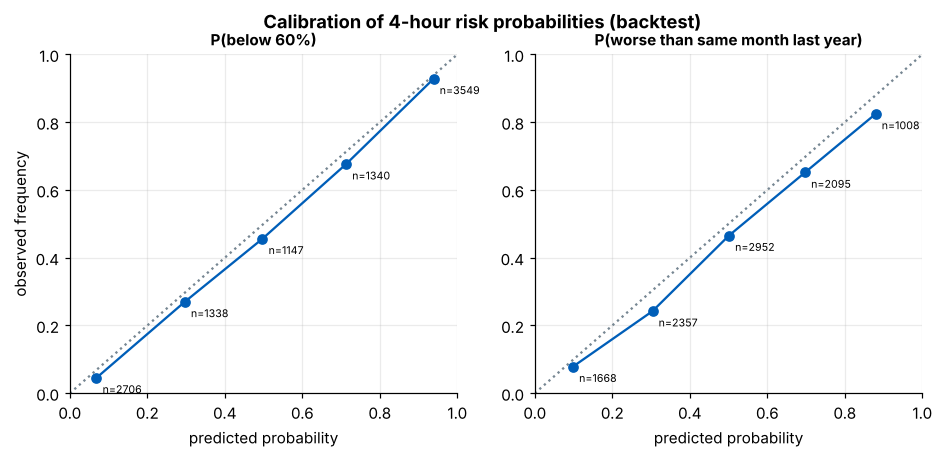

In [3]:
cal = pd.read_csv(RESULTS / "four_hour_calibration.csv")
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, ev in zip(axes, cal.event.unique()):
    c = cal[cal.event == ev]
    ax.plot([0, 1], [0, 1], ls=":", color=viz.NHS_GREY)
    ax.plot(c.predicted, c.observed, marker="o", color=viz.NHS_BLUE)
    for _, r in c.iterrows():
        ax.annotate(f"n={r.n}", (r.predicted, r.observed), fontsize=7, xytext=(4, -10), textcoords="offset points")
    ax.set_title(f"P({ev})", fontsize=10)
    ax.set_xlabel("predicted probability")
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
axes[0].set_ylabel("observed frequency")
fig.suptitle("Calibration of 4-hour risk probabilities (backtest)", fontweight="bold")
viz.save(fig, "06_calibration")

## 2. What drives the forecast

In [4]:
imp = pd.read_csv(RESULTS / "four_hour_feature_importance.csv", index_col=0)["gain_share"]
imp.round(3)

perf_last             0.389
perf_last3            0.232
nat_perf_last3        0.108
month                 0.054
perf_last12           0.038
perf_same_month_ly    0.035
trust_size            0.032
h                     0.029
admit_rate_last3      0.027
perf_yoy_change       0.024
demand_pressure_ly    0.018
demand_pressure       0.016
Name: gain_share, dtype: float64

A trust's own recent performance dominates: flow problems (beds, discharge, staffing) persist from month to month.
National pressure is next. The demand forecast adds little at monthly resolution. That fits notebook 02:
A&E footfall is not what peaks in winter.

## 3. This winter

In [5]:
lv = pd.read_csv(RESULTS / "four_hour_forecast.csv", parse_dates=["target_month"])
w = lv[lv.target_month.dt.month.isin([12, 1, 2])]
w = w[w.target_month <= w.target_month.min() + pd.DateOffset(months=2)]
risk = (w.groupby(["trust_code", "trust_name", "region_name"])
        .agg(median=("q50", "mean"), p_below_60=("p_below_60", "mean"), p_worse=("p_worse_than_ly", "mean"))
        .reset_index())
print(f"Winter {w.target_month.min():%b %Y}–{w.target_month.max():%b %Y}: median trust forecast {risk['median'].median():.1%}; "
      f"{(risk.p_below_60 > 0.5).sum()} of {len(risk)} trusts more likely than not below 60%; "
      f"{(risk.p_worse > 0.5).sum()} more likely than not worse than last winter")
risk.sort_values("p_worse", ascending=False).head(10).round(3)

Winter Dec 2026–Feb 2027: median trust forecast 58.7%; 69 of 120 trusts more likely than not below 60%; 56 more likely than not worse than last winter


,trust_code,trust_name,region_name,median,p_below_60,p_worse
23,RCF,Airedale NHS Foundation Trust,North East and Yorkshire,0.545,0.862,0.894
22,RCD,Harrogate And District NHS Foundation Trust,North East and Yorkshire,0.597,0.447,0.863
37,RGP,James Paget University Hospitals NHS Foundatio...,East of England,0.611,0.400,0.847
73,RNS,Northampton General Hospital NHS Trust,Midlands,0.558,0.821,0.813
95,RVR,Epsom And St Helier University Hospitals NHS T...,London,0.643,0.144,0.810
20,RC9,Bedfordshire Hospitals NHS Foundation Trust,East of England,0.591,0.548,0.799
9,RAE,Bradford Teaching Hospitals NHS Foundation Trust,North East and Yorkshire,0.736,0.007,0.794
74,RNZ,Salisbury NHS Foundation Trust,South West,0.520,0.925,0.778
80,RQX,Homerton Healthcare NHS Foundation Trust,London,0.775,0.000,0.777
98,RWA,Hull University Teaching Hospitals NHS Trust,North East and Yorkshire,0.425,0.999,0.776


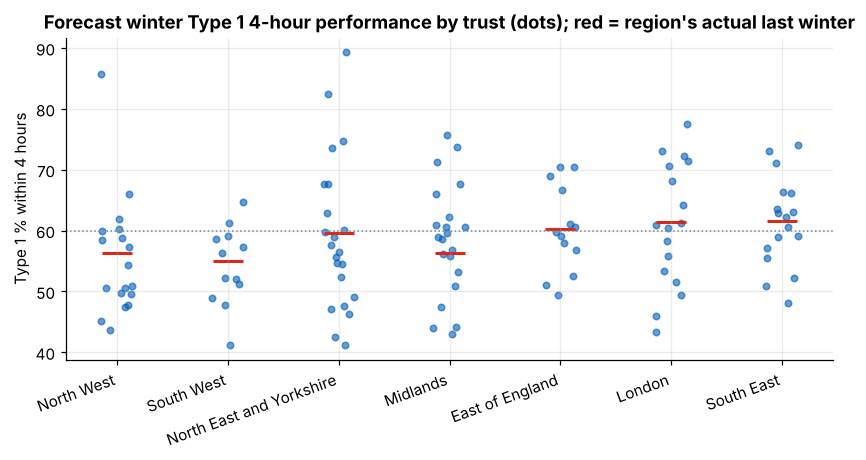

In [6]:
perf = pd.read_csv(PANEL, parse_dates=["month"])
reg_last = (perf[perf.month.dt.month.isin([12, 1, 2]) & (perf.month >= "2025-12-01") & (perf.month <= "2026-02-01")]
            .groupby("region_name")[["over_4h", "attendances_reported"]].sum())
reg_last = 1 - reg_last.over_4h / reg_last.attendances_reported
reg_now = risk.groupby("region_name")["median"].median()
order = reg_now.sort_values().index
fig, ax = plt.subplots(figsize=(9, 3.8))
for i, r in enumerate(order):
    pts = risk[risk.region_name == r]["median"]
    ax.scatter(np.full(len(pts), i) + np.random.default_rng(i).uniform(-0.15, 0.15, len(pts)), 100 * pts,
               color=viz.NHS_BLUE, alpha=0.6, s=18)
    ax.scatter(i, 100 * reg_last[r], marker="_", s=400, color=viz.NHS_RED, lw=2)
ax.axhline(60, color=viz.NHS_GREY, ls=":", lw=1)
ax.set_xticks(range(len(order)), order, rotation=20, ha="right")
ax.set_ylabel("Type 1 % within 4 hours")
ax.set_title("Forecast winter Type 1 4-hour performance by trust (dots); red = region's actual last winter")
viz.save(fig, "06_winter_risk")